# Cencus Data (code adopted from CYPLAN 88 Coursework)


In [6]:
pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import requests

# Pick ACS 5-year dataset and year.
CENSUS_YEAR = 2022
CENSUS_DATASET = "acs/acs5"
BASE_URL = f"https://api.census.gov/data/{CENSUS_YEAR}/{CENSUS_DATASET}"

In [3]:
# Download complete ACS variable metadata so you can browse everything available.
variables_url = f"{BASE_URL}/variables.json"
variables_payload = requests.get(variables_url, timeout=30).json()["variables"]

variables_df = (
    pd.DataFrame.from_dict(variables_payload, orient="index")
    .reset_index()
    .rename(columns={"index": "variable"})
)

for col in ["label", "concept", "predicateType", "group", "limit"]:
    if col not in variables_df.columns:
        variables_df[col] = None

variables_df = variables_df[["variable", "label", "concept", "predicateType", "group", "limit"]]
variables_df = variables_df.sort_values("variable").reset_index(drop=True)

print(f"Total variables in {CENSUS_DATASET} {CENSUS_YEAR}: {len(variables_df):,}")
variables_df.head(25)

Total variables in acs/acs5 2022: 28,193


,variable,label,concept,predicateType,group,limit
0,AIANHH,Geography,NaN,NaN,N/A,0
1,AIHHTL,Geography,NaN,NaN,N/A,0
2,AIRES,Geography,NaN,NaN,N/A,0
3,ANRC,Geography,NaN,NaN,N/A,0
4,B01001A_001E,Estimate!!Total:,Sex by Age (White Alone),int,B01001A,0
5,B01001A_002E,Estimate!!Total:!!Male:,Sex by Age (White Alone),int,B01001A,0
6,B01001A_003E,Estimate!!Total:!!Male:!!Under 5 years,Sex by Age (White Alone),int,B01001A,0
7,B01001A_004E,Estimate!!Total:!!Male:!!5 to 9 years,Sex by Age (White Alone),int,B01001A,0
8,B01001A_005E,Estimate!!Total:!!Male:!!10 to 14 years,Sex by Age (White Alone),int,B01001A,0
9,B01001A_006E,Estimate!!Total:!!Male:!!15 to 17 years,Sex by Age (White Alone),int,B01001A,0


In [4]:
# Search helper for variable discovery.
def find_variables(keyword, n=50):
    k = keyword.lower().strip()
    out = variables_df[
        variables_df["label"].fillna("").str.lower().str.contains(k)
        | variables_df["concept"].fillna("").str.lower().str.contains(k)
        | variables_df["variable"].fillna("").str.lower().str.contains(k)
    ]
    return out.head(n)

find_variables("median household income", n=20)

,variable,label,concept,predicateType,group,limit
11409,B19013A_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013A,0
11410,B19013B_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013B,0
11411,B19013C_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013C,0
11412,B19013D_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013D,0
11413,B19013E_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013E,0
11414,B19013F_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013F,0
11415,B19013G_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013G,0
11416,B19013H_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013H,0
11417,B19013I_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013I,0
11418,B19013_001E,Estimate!!Median household income in the past ...,Median Household Income in the Past 12 Months ...,int,B19013,0


In [5]:
# Pull Chicago city-level ACS values.
# Chicago place FIPS is 14000 in Illinois (state FIPS 17).
selected_vars = [
    "B01003_001E",  # Total population
    "B19013_001E",  # Median household income
    "B02001_002E",  # White alone
    "B02001_003E",  # Black alone
    "B02001_005E",  # Asian alone
]

params = {
    "get": "NAME," + ",".join(selected_vars),
    "for": "place:14000",
    "in": "state:17",
}

resp = requests.get(BASE_URL, params=params, timeout=30)
resp.raise_for_status()
rows = resp.json()

chicago_city_df = pd.DataFrame(rows[1:], columns=rows[0])
for v in selected_vars:
    chicago_city_df[v] = pd.to_numeric(chicago_city_df[v], errors="coerce")

chicago_city_df

,NAME,B01003_001E,B19013_001E,B02001_002E,B02001_003E,B02001_005E,state,place
0,"Chicago city, Illinois",2721914,71673,1154279,784078,190801,17,14000


In [6]:
# Optional: tract-level pull for Cook County (includes Chicago and non-Chicago tracts).
tract_params = {
    "get": "NAME," + ",".join(selected_vars),
    "for": "tract:*",
    "in": "state:17 county:031",  # Illinois, Cook County
}

tract_resp = requests.get(BASE_URL, params=tract_params, timeout=60)
tract_resp.raise_for_status()
tract_rows = tract_resp.json()

cook_tracts_df = pd.DataFrame(tract_rows[1:], columns=tract_rows[0])
for v in selected_vars:
    cook_tracts_df[v] = pd.to_numeric(cook_tracts_df[v], errors="coerce")

print(f"Cook County tract rows: {len(cook_tracts_df):,}")
cook_tracts_df.head()

Cook County tract rows: 1,332


,NAME,B01003_001E,B19013_001E,B02001_002E,B02001_003E,B02001_005E,state,county,tract
0,Census Tract 101; Cook County; Illinois,4284,68196,1915,1376,94,17,031,010100
1,Census Tract 102.01; Cook County; Illinois,8210,61071,2087,3009,298,17,031,010201
2,Census Tract 102.02; Cook County; Illinois,2865,58698,892,945,312,17,031,010202
3,Census Tract 103; Cook County; Illinois,6237,68336,3343,1473,338,17,031,010300
4,Census Tract 104; Cook County; Illinois,4473,48630,3578,354,213,17,031,010400


In [7]:
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cenpy
import geopandas
from cenpy import products
import matplotlib as mpl

c:\Users\Tyler Marino\OneDrive\Desktop\EOData\sensornetwork\SensorsNetwork_Venv\Lib\site-packages\fuzzywuzzy\fuzz.py:11: UserWarning: Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning
  warnings.warn('Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning')


In [8]:
### Build Chicago tract GeoDataFrame and cleaned columns for mapping
import geopandas as gpd
import matplotlib.pyplot as plt

# TIGER/Line geometry sources (2022 to match ACS year).
tract_url = "https://www2.census.gov/geo/tiger/TIGER2022/TRACT/tl_2022_17_tract.zip"
place_url = "https://www2.census.gov/geo/tiger/TIGER2022/PLACE/tl_2022_17_place.zip"

il_tracts = gpd.read_file(tract_url)
cook_tract_geoms = il_tracts[il_tracts["COUNTYFP"] == "031"].copy()

# Remove mostly water/open-water tracts that distort the plot extent.
cook_tract_geoms["ALAND"] = pd.to_numeric(cook_tract_geoms["ALAND"], errors="coerce")
cook_tract_geoms = cook_tract_geoms[cook_tract_geoms["ALAND"] > 0].copy()

# Chicago place boundary (PLACEFP 14000).
il_places = gpd.read_file(place_url)
chicago_boundary = il_places[il_places["PLACEFP"] == "14000"][["geometry"]].copy()

# Keep tracts touching Chicago boundary and merge ACS attributes.
chicago_tract_geoms = gpd.sjoin(cook_tract_geoms, chicago_boundary, how="inner", predicate="intersects")
chicago_tract_geoms["tract"] = chicago_tract_geoms["TRACTCE"].astype(str).str.zfill(6)

cook_tracts_df["tract"] = cook_tracts_df["tract"].astype(str).str.zfill(6)
chicago_tracts_gdf = chicago_tract_geoms.merge(cook_tracts_df, how="left", on="tract")

# Friendly names used in plots.
variables_dict = {
    "B01003_001E": "Population",
    "B02001_002E": "White Population",
    "B02001_003E": "Black Population",
    "B02001_005E": "Asian Population",
    "B19013_001E": "Median HH Income",
}

for c in variables_dict:
    chicago_tracts_gdf[c] = pd.to_numeric(chicago_tracts_gdf[c], errors="coerce")

# Census uses negative sentinel values for some missing estimates; drop those.
chicago_tracts_gdf.loc[chicago_tracts_gdf["B19013_001E"] < 0, "B19013_001E"] = pd.NA

chicago_named = chicago_tracts_gdf.rename(columns=variables_dict)
master_columns = list(variables_dict.values())
percent_columns_list = ["Population", "White Population", "Black Population", "Asian Population"]

def percent_columns(df, columns):
    df_percent = df.copy()
    for column in columns:
        total = df_percent[column].sum(skipna=True)
        if total and total > 0:
            df_percent[column] = df_percent[column] / total
    return df_percent

chicago_percents = percent_columns(chicago_named, percent_columns_list)
print(f"Chicago tract rows for mapping: {len(chicago_percents):,}")

Chicago tract rows for mapping: 870


In [9]:
chicago_percents.head(5)

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME_x,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,...,index_right,tract,NAME_y,Population,Median HH Income,White Population,Black Population,Asian Population,state,county
0,17,031,030101,17031030101,301.01,Census Tract 301.01,G5020,S,127283,110999,...,587,030101,Census Tract 301.01; Cook County; Illinois,0.001140,50696.0,0.001034,0.001089,0.003618,17,031
1,17,031,030701,17031030701,307.01,Census Tract 307.01,G5020,S,69878,0,...,587,030701,Census Tract 307.01; Cook County; Illinois,0.000489,47614.0,0.000556,0.000651,0.000608,17,031
2,17,031,070103,17031070103,701.03,Census Tract 701.03,G5020,S,69094,0,...,587,070103,Census Tract 701.03; Cook County; Illinois,0.000466,78125.0,0.000845,0.000128,0.000556,17,031
3,17,031,807900,17031807900,8079,Census Tract 8079,G5020,S,2013730,0,...,587,807900,Census Tract 8079; Cook County; Illinois,0.001408,108351.0,0.002171,0.000311,0.003941,17,031
4,17,031,808001,17031808001,8080.01,Census Tract 8080.01,G5020,S,2202703,0,...,587,808001,Census Tract 8080.01; Cook County; Illinois,0.001161,93958.0,0.001631,0.000053,0.005110,17,031


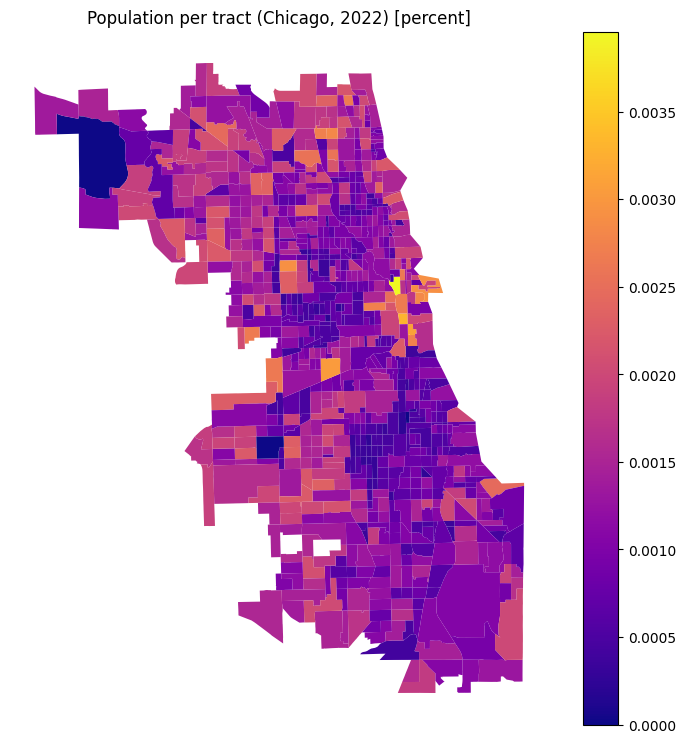

_________________________________________________________________________


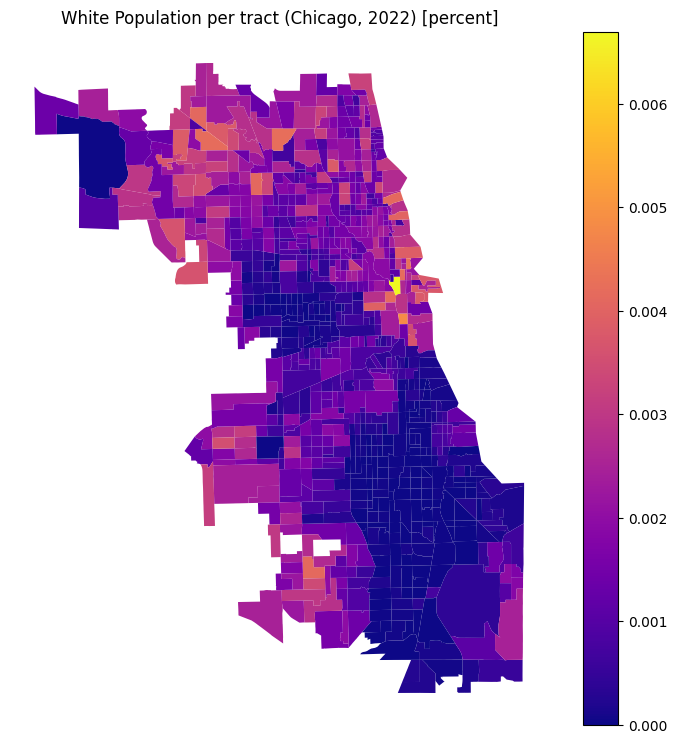

_________________________________________________________________________


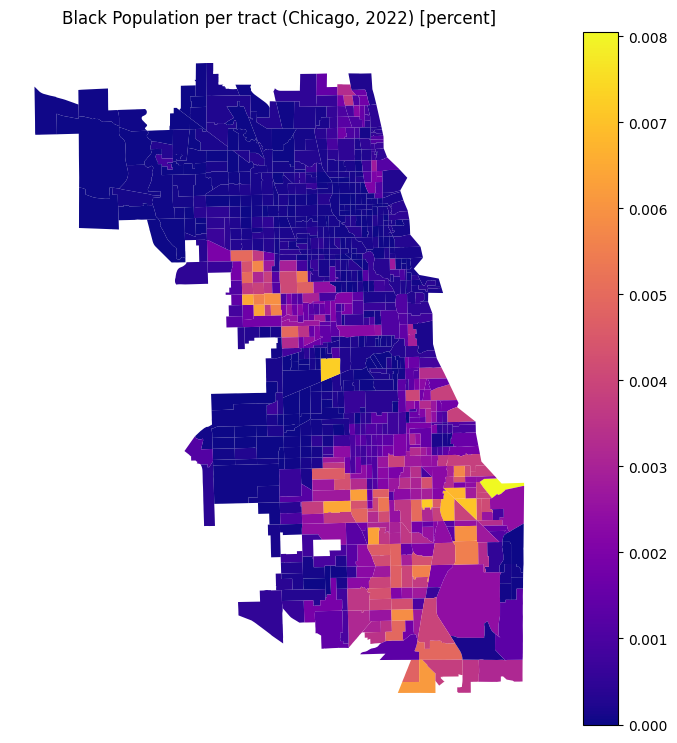

_________________________________________________________________________


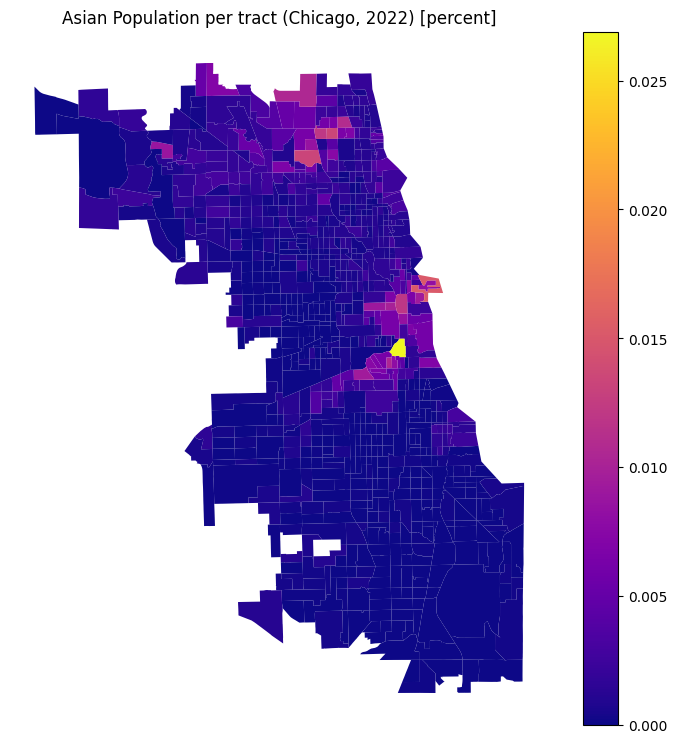

_________________________________________________________________________


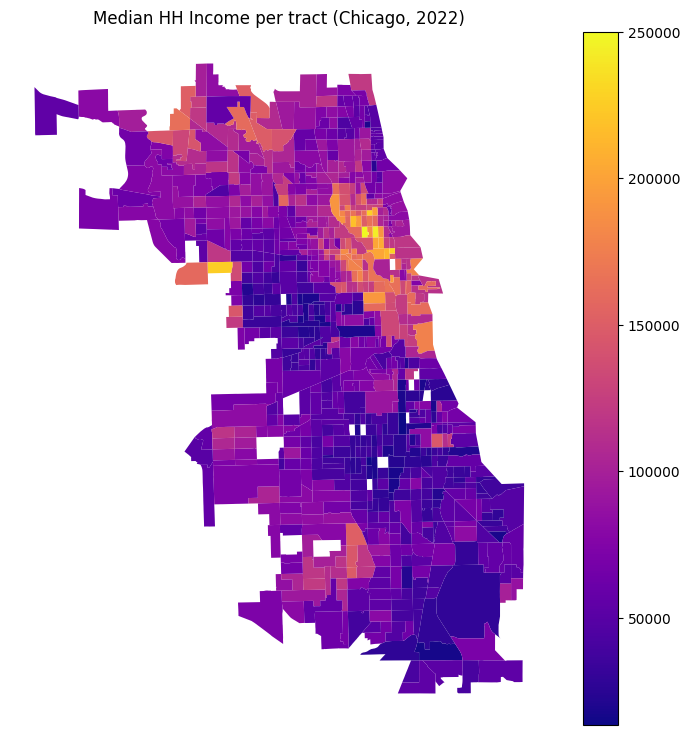

_________________________________________________________________________


In [10]:
for column in master_columns:
    to_plot = chicago_percents.dropna(subset=[column], axis=0)
    ax = to_plot.plot(column=column, cmap="plasma", legend=True, figsize=(9, 9))

    if column in percent_columns_list:
        ax.set_title(f"{column} per tract (Chicago, {CENSUS_YEAR}) [percent]")
    else:
        ax.set_title(f"{column} per tract (Chicago, {CENSUS_YEAR})")

    ax.set_axis_off()
    plt.show()
    print("_________________________________________________________________________")

## Additional Mapping Additions

1. Race share within each tract (not city-total share)
2. Interactive map with hover tooltips
3. Side-by-side two-year comparison (2017 vs 2022)

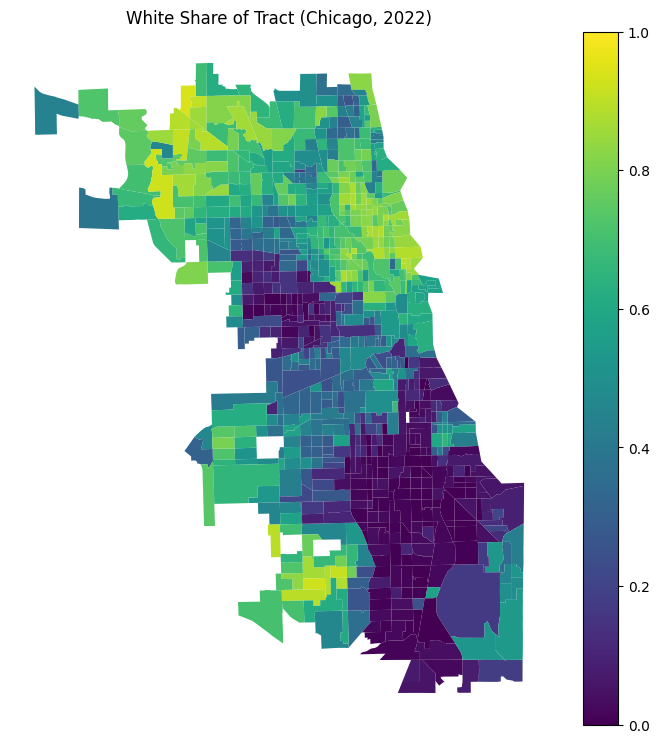

_________________________________________________________________________


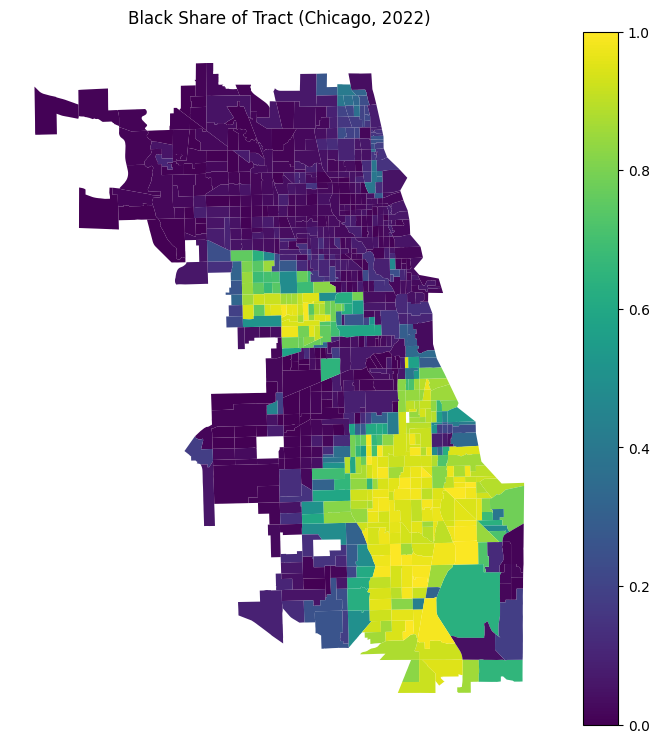

_________________________________________________________________________


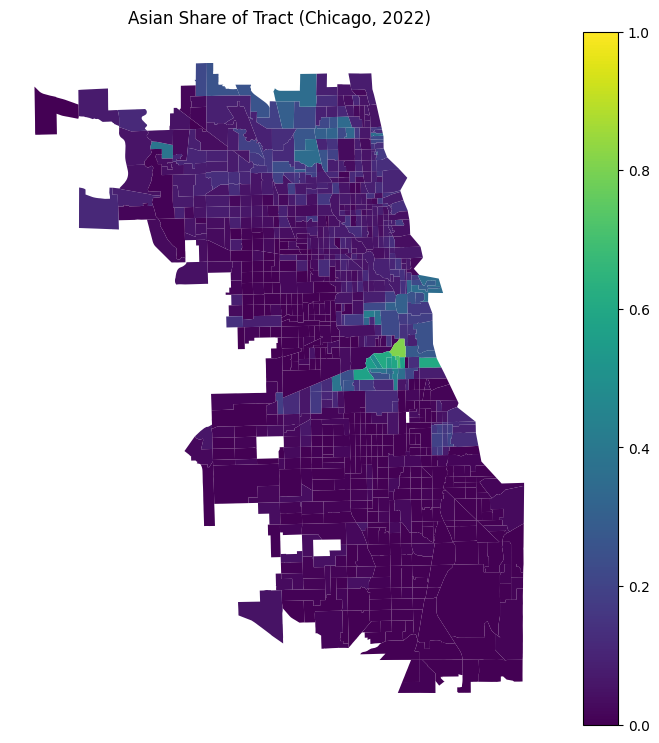

_________________________________________________________________________


In [11]:
# 1) Percent within each tract (composition share)
chicago_within = chicago_named.copy()

# Shares use tract total population as denominator.
chicago_within["White Share of Tract"] = chicago_within["White Population"] / chicago_within["Population"]
chicago_within["Black Share of Tract"] = chicago_within["Black Population"] / chicago_within["Population"]
chicago_within["Asian Share of Tract"] = chicago_within["Asian Population"] / chicago_within["Population"]

within_columns = ["White Share of Tract", "Black Share of Tract", "Asian Share of Tract"]
for column in within_columns:
    ax = chicago_within.plot(column=column, cmap="viridis", legend=True, figsize=(9, 9), vmin=0, vmax=1)
    ax.set_title(f"{column} (Chicago, {CENSUS_YEAR})")
    ax.set_axis_off()
    plt.show()
    print("_________________________________________________________________________")

In [12]:
# 2) Interactive map with hover tooltips (Folium)
import folium

interactive_df = chicago_within[[
    "tract",
    "Population",
    "Median HH Income",
    "White Share of Tract",
    "Black Share of Tract",
    "Asian Share of Tract",
    "geometry",
]].copy()

interactive_df = interactive_df.to_crs(epsg=4326)
map_center = [41.8781, -87.6298]

m = folium.Map(location=map_center, zoom_start=10, tiles="cartodbpositron")

folium.Choropleth(
    geo_data=interactive_df.to_json(),
    data=interactive_df,
    columns=["tract", "Median HH Income"],
    key_on="feature.properties.tract",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.25,
    legend_name=f"Median HH Income ({CENSUS_YEAR} ACS5)",
    nan_fill_color="lightgray",
).add_to(m)

tooltip = folium.features.GeoJsonTooltip(
    fields=["tract", "Population", "Median HH Income", "White Share of Tract", "Black Share of Tract", "Asian Share of Tract"],
    aliases=["Tract", "Population", "Median HH Income", "White Share", "Black Share", "Asian Share"],
    localize=True,
    labels=True,
    sticky=False,
)

folium.GeoJson(interactive_df.to_json(), tooltip=tooltip, name="Chicago Tracts").add_to(m)
folium.LayerControl().add_to(m)
m

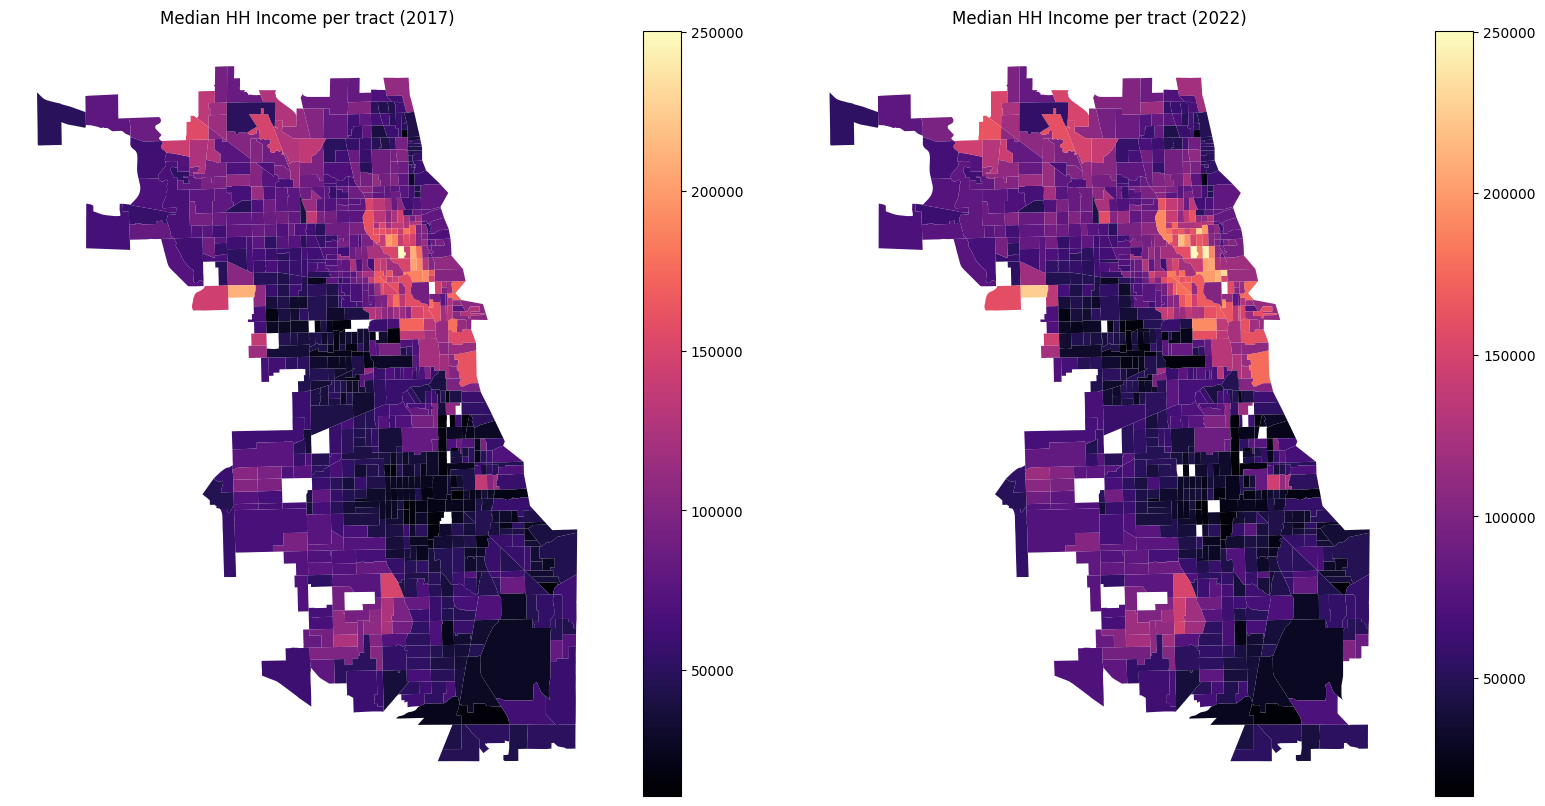

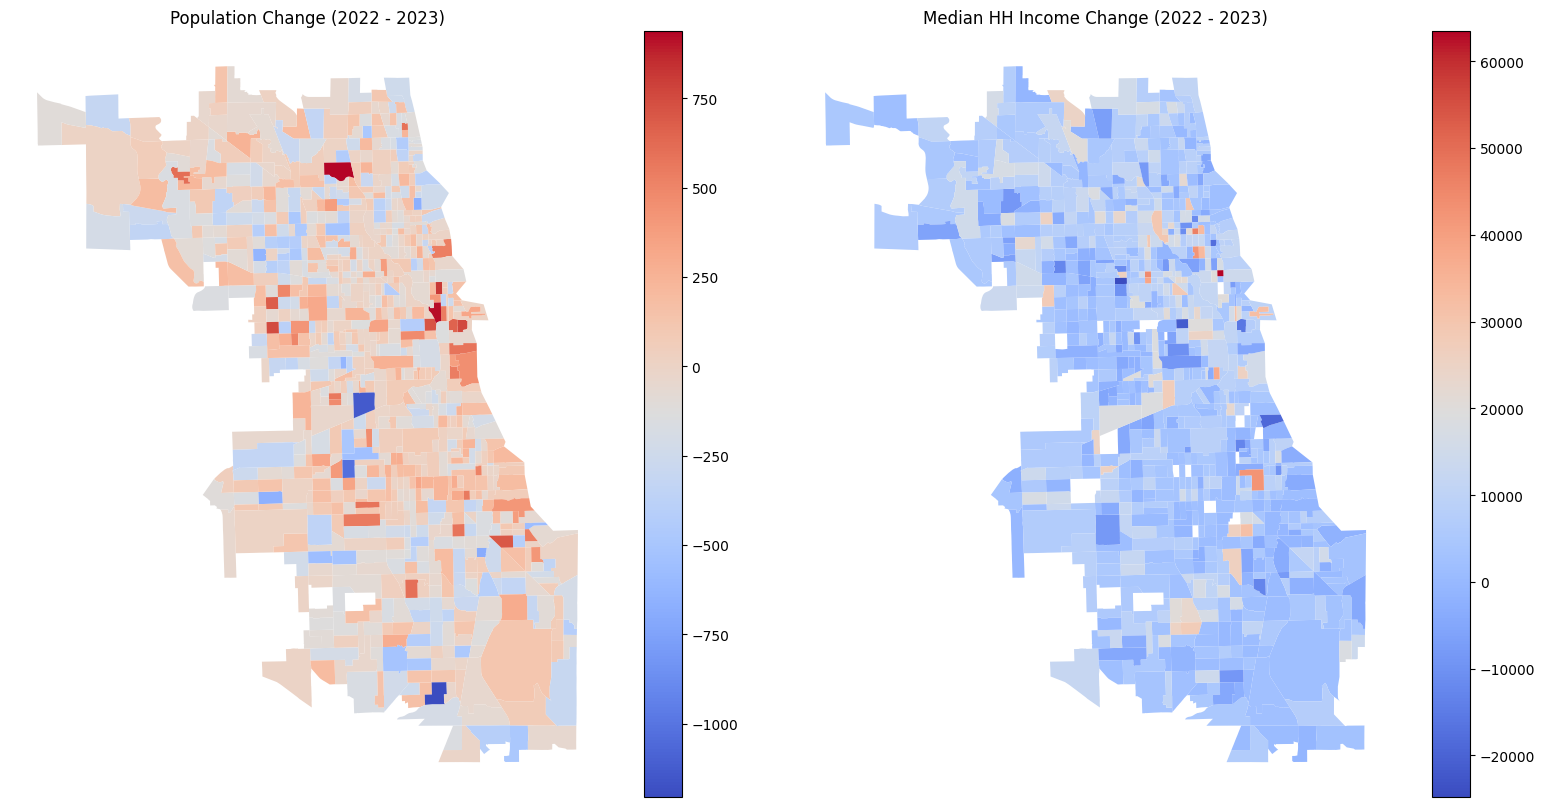

In [16]:
# 3) Side-by-side two-year comparison (2017 vs 2022)
def fetch_cook_tracts(year, vars_list):
    base = f"https://api.census.gov/data/{year}/acs/acs5"
    p = {
        "get": "NAME," + ",".join(vars_list),
        "for": "tract:*",
        "in": "state:17 county:031",
    }
    r = requests.get(base, params=p, timeout=60)
    r.raise_for_status()
    raw = r.json()
    df = pd.DataFrame(raw[1:], columns=raw[0])
    df["tract"] = df["tract"].astype(str).str.zfill(6)
    for vv in vars_list:
        df[vv] = pd.to_numeric(df[vv], errors="coerce")
    df.loc[df["B19013_001E"] < 0, "B19013_001E"] = pd.NA
    return df

year_a = 2021
year_b = 2022
compare_vars = ["B01003_001E", "B19013_001E"]

cook_2017 = fetch_cook_tracts(year_a, compare_vars)
cook_2022 = fetch_cook_tracts(year_b, compare_vars)

compare_2017 = chicago_tract_geoms[["tract", "geometry"]].merge(cook_2017, how="left", on="tract")
compare_2022 = chicago_tract_geoms[["tract", "geometry"]].merge(cook_2022, how="left", on="tract")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
compare_2017.plot(column="B19013_001E", cmap="magma", legend=True, ax=axes[0])
axes[0].set_title("Median HH Income per tract (2017)")
axes[0].set_axis_off()

compare_2022.plot(column="B19013_001E", cmap="magma", legend=True, ax=axes[1])
axes[1].set_title("Median HH Income per tract (2022)")
axes[1].set_axis_off()
plt.tight_layout()
plt.show()

change_df = compare_2022[["tract", "geometry", "B01003_001E", "B19013_001E"]].merge(
    compare_2017[["tract", "B01003_001E", "B19013_001E"]],
    on="tract",
    how="left",
    suffixes=("_2022", "_2023"),
)
change_df["Population Change"] = change_df["B01003_001E_2022"] - change_df["B01003_001E_2023"]
change_df["Income Change"] = change_df["B19013_001E_2022"] - change_df["B19013_001E_2023"]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
change_df.plot(column="Population Change", cmap="coolwarm", legend=True, ax=axes[0])
axes[0].set_title("Population Change (2022 - 2023)")
axes[0].set_axis_off()

change_df.plot(column="Income Change", cmap="coolwarm", legend=True, ax=axes[1])
axes[1].set_title("Median HH Income Change (2022 - 2023)")
axes[1].set_axis_off()
plt.tight_layout()
plt.show()

In [31]:
# Yearly Differences and Clustering Add-ons
# 1) Year-over-year differences for each selected variable
# 2) KMeans clustering with variable toggles

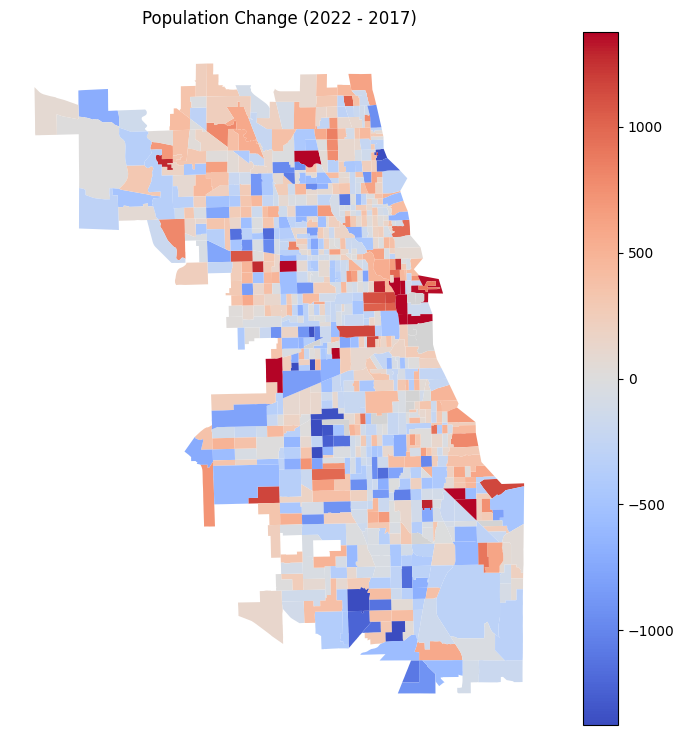

_________________________________________________________________________


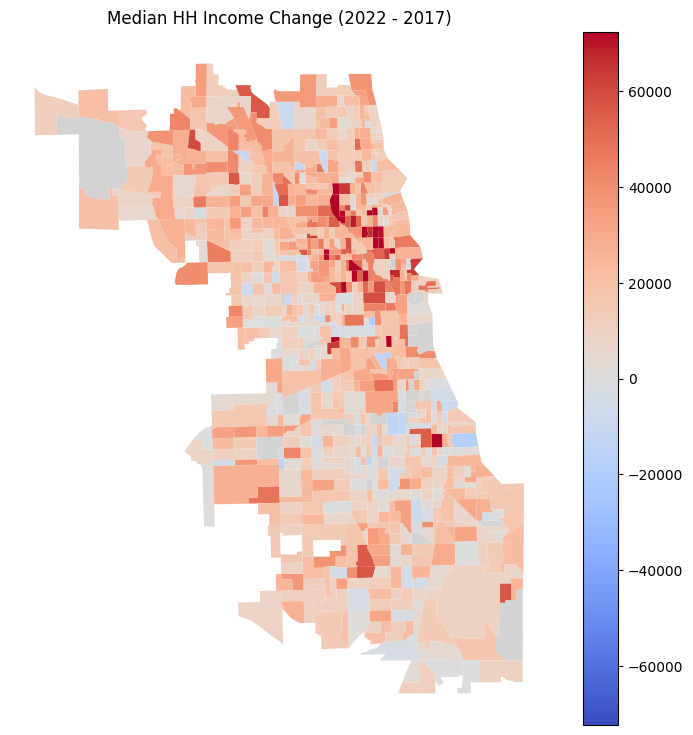

_________________________________________________________________________


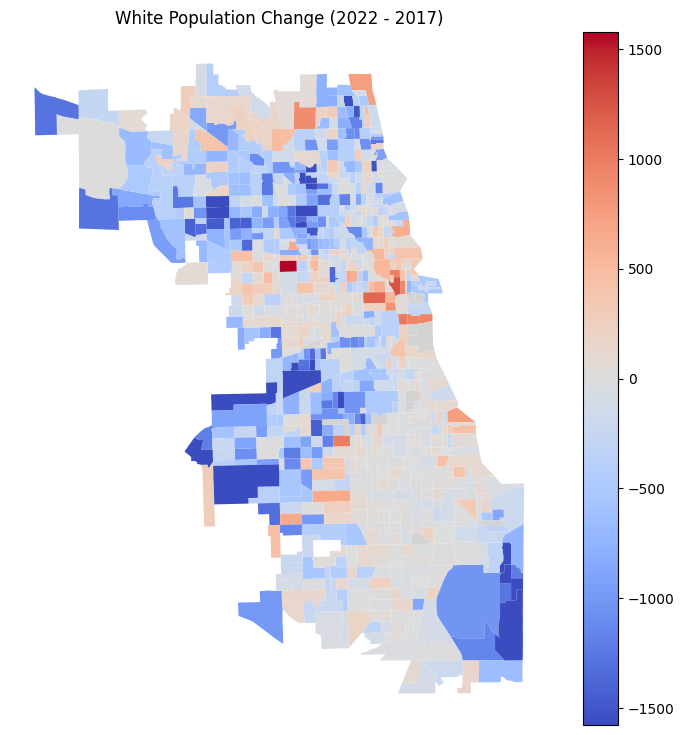

_________________________________________________________________________


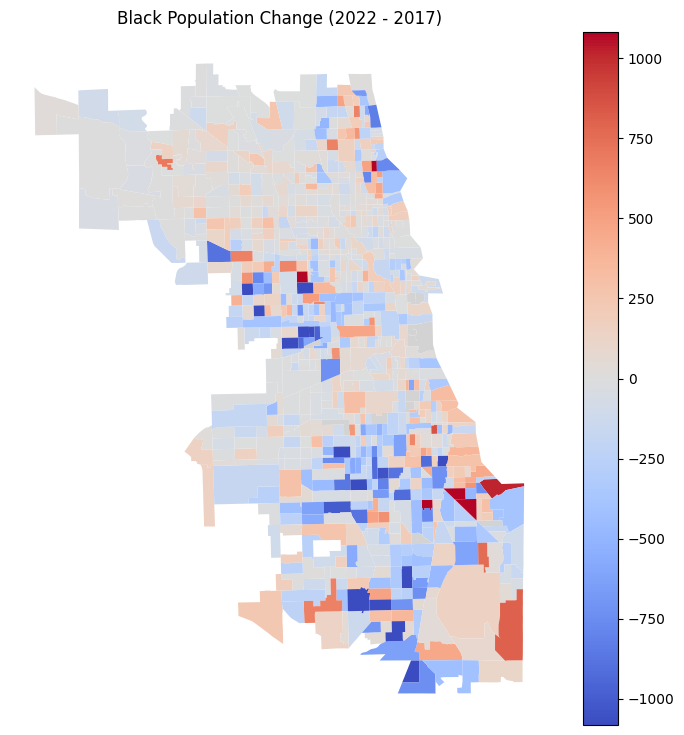

_________________________________________________________________________


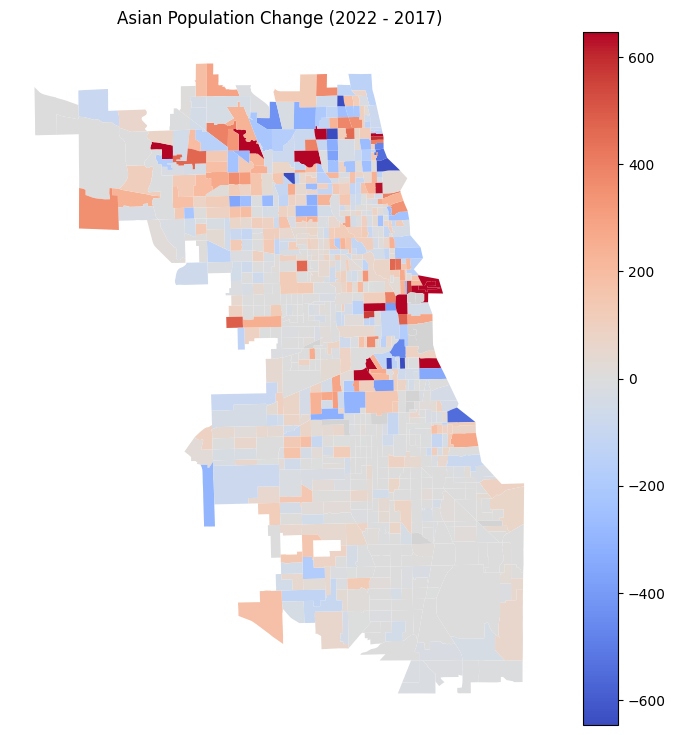

_________________________________________________________________________


In [32]:
# A) Differences between years for each selected variable

year_1 = 2017
year_2 = 2022

# Use all selected variables from your ACS pull.
all_compare_vars = selected_vars.copy()

df_y1 = fetch_cook_tracts(year_1, all_compare_vars)
df_y2 = fetch_cook_tracts(year_2, all_compare_vars)

# Keep Chicago tract geometry and join both years.
changes_all = chicago_tract_geoms[["tract", "geometry"]].merge(
    df_y2[["tract"] + all_compare_vars], on="tract", how="left"
).merge(
    df_y1[["tract"] + all_compare_vars], on="tract", how="left", suffixes=(f"_{year_2}", f"_{year_1}")
)

# Compute change column for every selected variable.
for var_code in all_compare_vars:
    label = variables_dict.get(var_code, var_code)
    changes_all[f"{label} Change"] = changes_all[f"{var_code}_{year_2}"] - changes_all[f"{var_code}_{year_1}"]

change_columns = [f"{variables_dict.get(v, v)} Change" for v in all_compare_vars]

# Quick summary table.
change_summary = changes_all[change_columns].agg(["mean", "median", "min", "max"]).T.sort_index()
change_summary

# Plot a map for each change variable.
for col in change_columns:
    max_abs = changes_all[col].abs().quantile(0.98)
    if pd.notna(max_abs) and max_abs > 0:
        vmin, vmax = -max_abs, max_abs
    else:
        vmin, vmax = None, None

    ax = changes_all.plot(
        column=col,
        cmap="coolwarm",
        legend=True,
        figsize=(9, 9),
        vmin=vmin,
        vmax=vmax,
        missing_kwds={"color": "lightgray", "label": "No data"},
    )
    ax.set_title(f"{col} ({year_2} - {year_1})")
    ax.set_axis_off()
    plt.show()
    print("_________________________________________________________________________")

In [34]:
# B) KMeans clustering with variable toggle and cluster count controls
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import ipywidgets as widgets
from IPython.display import display

def run_chicago_kmeans(include_vars, n_clusters=5, year=2022, random_state=42):
    # Pull selected year for selected variables.
    raw = fetch_cook_tracts(year, include_vars)
    gdf = chicago_tract_geoms[["tract", "geometry"]].merge(raw[["tract"] + include_vars], on="tract", how="left")

    # Clean and prepare model matrix.
    X = gdf[include_vars].apply(pd.to_numeric, errors="coerce")
    X = X.dropna(axis=0, how="any")

    if X.empty:
        raise ValueError("No rows available after dropping NA values for selected variables.")

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=20)
    labels = model.fit_predict(X_scaled)

    out = gdf.copy()
    out["cluster"] = pd.NA
    out.loc[X.index, "cluster"] = labels.astype(int)

    # Cluster map
    ax = out.plot(
        column="cluster",
        categorical=True,
        cmap="tab20",
        legend=True,
        figsize=(10, 10),
        missing_kwds={"color": "lightgray", "label": "No data"},
    )
    var_names = [variables_dict.get(v, v) for v in include_vars]
    ax.set_title(f"Chicago KMeans Clusters ({year}) | k={n_clusters}\nVars: {', '.join(var_names)}")
    ax.set_axis_off()
    plt.show()

    return out, model

# Interactive controls (toggle variables + cluster count)
variable_options = [(variables_dict.get(v, v), v) for v in selected_vars]

var_selector = widgets.SelectMultiple(
    options=variable_options,
    value=tuple([v for _, v in variable_options]),
    description="Variables",
    rows=min(8, len(variable_options)),
)

k_slider = widgets.IntSlider(value=5, min=2, max=10, step=1, description="k")
year_dropdown = widgets.Dropdown(options=[2017, 2018, 2019, 2020, 2021, 2022], value=2022, description="Year")
run_button = widgets.Button(description="Run KMeans", button_style="success")
output = widgets.Output()

def on_run_clicked(_):
    with output:
        output.clear_output(wait=True)
        chosen = list(var_selector.value)
        if not chosen:
            print("Select at least one variable.")
            return
        clustered_gdf, kmeans_model = run_chicago_kmeans(chosen, n_clusters=k_slider.value, year=year_dropdown.value)
        print(f"Rows clustered: {clustered_gdf['cluster'].notna().sum():,}")
        print("Centroids (scaled feature space):")
        print(kmeans_model.cluster_centers_)

run_button.on_click(on_run_clicked)

display(widgets.VBox([var_selector, k_slider, year_dropdown, run_button, output]))

# Example matching your style:
# kmeans2 = KMeans(n_clusters=2)
# kmeans2.fit(df_clustering2[new_columns])
# kmeans5 = KMeans(n_clusters=5)
# kmeans5.fit(df_clustering5[master_columns])

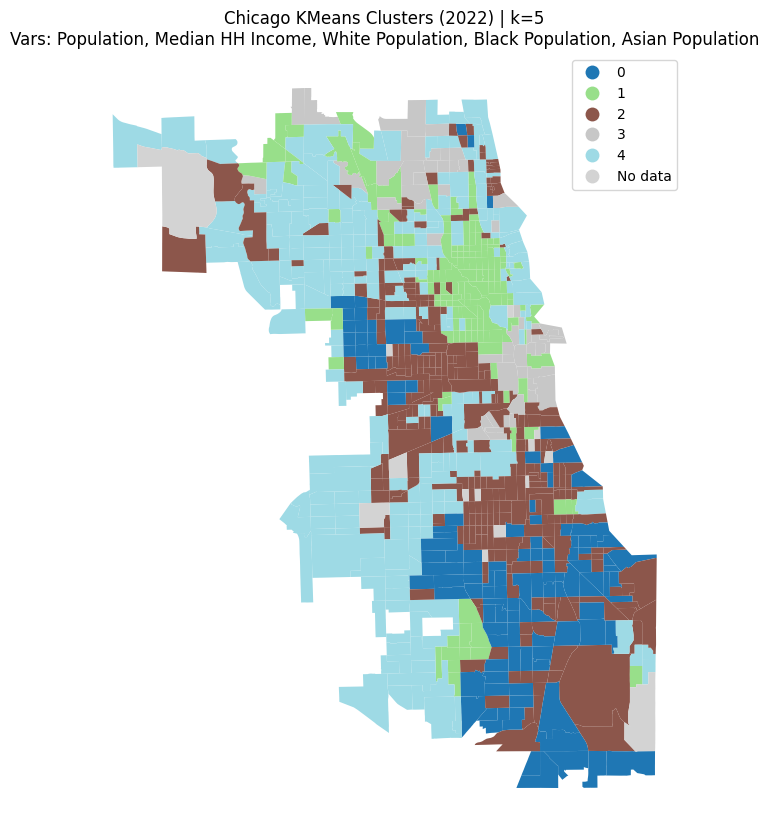

Example KMeans complete. Cluster counts:
cluster
0    120
1    147
2    305
3     51
4    233
Name: count, dtype: int64


In [35]:
# Optional direct-run example (non-widget) to mirror your original KMeans style
clustered_example, kmeans_example = run_chicago_kmeans(selected_vars, n_clusters=5, year=2022)
print("Example KMeans complete. Cluster counts:")
print(clustered_example["cluster"].value_counts(dropna=True).sort_index())